
Fertilizer Recommendation Model — v3 (strengthened)
Changes vs v2:
  1. Engineered NPK-ratio features (N/P, N/K, P/K, N+P+K total) — these are what
     agronomically separate NPK/Urea/MOP/SSP, and the raw values alone don't
     expose the ratio signal to a tree model as directly as we'd like.
  2. SMOTE applied to TRAIN split only (never val/test) to fix class imbalance
     properly, instead of just sample_weight re-weighting.
  3. Slightly deeper trees + more estimators since SMOTE gives more minority
     signal to learn from.
  4. Confidence-stratified evaluation: accuracy broken out by prediction
     confidence bucket, so you can honestly report "at >80% confidence we're
     X% accurate" instead of one blended number.
  5. Same leakage-safe split discipline as v2 (split first, fit preprocessing
     on train only).



## Importing dependencies

In [12]:
!python -m pip install imbalanced-learn


[notice] A new release of pip is available: 26.0.1 -> 26.1.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [26]:
import numpy as np
import pandas as pd
import warnings
warnings.filterwarnings("ignore")
from typing import Any, cast
from sklearn.preprocessing import label_binarize
import seaborn as sns
sns.set_style("whitegrid")
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, f1_score
from imblearn.over_sampling import SMOTE
import xgboost as xgb
import joblib

RANDOM_STATE = 42

## Load Data

In [14]:
df = pd.read_csv("../Dataset/fertilizer_recommendation.csv")
print("Shape:", df.shape)

TARGET = "Recommended_Fertilizer"
onehot_cols = ["Soil_Type", "Crop_Type", "Season", "Irrigation_Type", "Previous_Crop", "Region"]
ordinal_col = "Crop_Growth_Stage"
base_numeric_cols = [
    "Soil_pH", "Soil_Moisture", "Organic_Carbon", "Electrical_Conductivity",
    "Nitrogen_Level", "Phosphorus_Level", "Potassium_Level", "Temperature",
    "Humidity", "Rainfall", "Fertilizer_Used_Last_Season", "Yield_Last_Season",
]

stage_mapping = {"Sowing": 0, "Vegetative": 1, "Flowering": 2, "Harvest": 3}
df[ordinal_col] = df[ordinal_col].map(stage_mapping)

Shape: (10000, 20)


### Feature engineering: NPK ratios (added BEFORE split — these are deterministic functions of raw inputs, not learned from data, so no leakage)

In [15]:
EPS = 1e-3

def add_npk_features(frame):
    frame = frame.copy()
    frame["NP_ratio"] = frame["Nitrogen_Level"] / (frame["Phosphorus_Level"] + EPS)
    frame["NK_ratio"] = frame["Nitrogen_Level"] / (frame["Potassium_Level"] + EPS)
    frame["PK_ratio"] = frame["Phosphorus_Level"] / (frame["Potassium_Level"] + EPS)
    frame["NPK_total"] = frame["Nitrogen_Level"] + frame["Phosphorus_Level"] + frame["Potassium_Level"]
    frame["N_share"] = frame["Nitrogen_Level"] / (frame["NPK_total"] + EPS)
    frame["P_share"] = frame["Phosphorus_Level"] / (frame["NPK_total"] + EPS)
    frame["K_share"] = frame["Potassium_Level"] / (frame["NPK_total"] + EPS)
    return frame

df = add_npk_features(df)
engineered_cols = ["NP_ratio", "NK_ratio", "PK_ratio", "NPK_total", "N_share", "P_share", "K_share"]
numeric_cols = base_numeric_cols + engineered_cols

### Split FIRST (raw data), preprocess AFTER — leakage-safe. 60% train / 20% val (early stopping) / 20% test (final, untouched).

In [16]:
X = df.drop(columns=[TARGET])
y_raw = df[TARGET]

label_encoder = LabelEncoder()
y = label_encoder.fit_transform(y_raw)
print("Classes:", dict(zip(label_encoder.classes_, range(len(label_encoder.classes_)))))

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.4, stratify=y, random_state=RANDOM_STATE
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.5, stratify=y_temp, random_state=RANDOM_STATE
)
print(f"Train: {X_train.shape[0]}  Val: {X_val.shape[0]}  Test: {X_test.shape[0]}")
print("Train class counts:\n", pd.Series(y_train).value_counts())

Classes: {'Compost': 0, 'DAP': 1, 'MOP': 2, 'NPK': 3, 'SSP': 4, 'Urea': 5, 'Zinc Sulphate': 6}
Train: 6000  Val: 2000  Test: 2000
Train class counts:
 5    1861
1    1752
2     845
0     597
6     451
3     385
4     109
Name: count, dtype: int64


### Fit encoders/scaler on TRAIN ONLY, then transform train/val/test

In [17]:
onehot = OneHotEncoder(sparse_output=False, handle_unknown="ignore")
onehot.fit(X_train[onehot_cols])

def encode_onehot(frame):
    arr = np.asarray(onehot.transform(frame[onehot_cols]))
    cols = onehot.get_feature_names_out(onehot_cols)
    enc_df = pd.DataFrame(arr, columns=cols, index=frame.index, dtype=int)
    return pd.concat([frame.drop(columns=onehot_cols), enc_df], axis=1)

X_train = encode_onehot(X_train)
X_val = encode_onehot(X_val)
X_test = encode_onehot(X_test)

scaler = StandardScaler()
scaler.fit(X_train[numeric_cols + [ordinal_col]])

for frame in (X_train, X_val, X_test):
    frame[numeric_cols + [ordinal_col]] = scaler.transform(frame[numeric_cols + [ordinal_col]])

X_val = X_val.reindex(columns=X_train.columns, fill_value=0)
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)


### SMOTE — oversample minority classes in TRAIN ONLY (never val/test).
### This is the key fix vs v2's sample_weight-only approach: SMOTE actually
### synthesizes new minority examples so the model sees more decision-boundary
### signal for SSP/NPK/Zinc Sulphate, instead of just up-weighting the few it has.

In [18]:
print("\nBefore SMOTE:", pd.Series(y_train).value_counts().to_dict())
smote = SMOTE(random_state=RANDOM_STATE, k_neighbors=5)
resampled = cast(tuple[Any, Any], smote.fit_resample(X_train, y_train))
X_train_res, y_train_res = resampled
y_train_res = np.asarray(y_train_res)
print("After SMOTE:", pd.Series(y_train_res).value_counts().to_dict())


Before SMOTE: {5: 1861, 1: 1752, 2: 845, 0: 597, 6: 451, 3: 385, 4: 109}
After SMOTE: {5: 1861, 1: 1861, 2: 1861, 6: 1861, 3: 1861, 0: 1861, 4: 1861}


### Baseline — Logistic Regression on SMOTE'd data, for comparison

In [19]:
baseline = LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)
baseline.fit(X_train_res, y_train_res)
baseline_pred = baseline.predict(X_test)
print("\n=== Baseline: Logistic Regression (SMOTE) ===")
print("Accuracy:", accuracy_score(y_test, baseline_pred))
print("Macro F1:", f1_score(y_test, baseline_pred, average="macro"))
print(classification_report(y_test, baseline_pred, target_names=label_encoder.classes_))


=== Baseline: Logistic Regression (SMOTE) ===
Accuracy: 0.8
Macro F1: 0.6404078736984095
               precision    recall  f1-score   support

      Compost       0.70      0.81      0.75       200
          DAP       0.87      0.89      0.88       584
          MOP       0.80      0.80      0.80       281
          NPK       0.38      0.34      0.36       128
          SSP       0.15      0.05      0.08        37
         Urea       0.88      0.86      0.87       620
Zinc Sulphate       0.72      0.75      0.73       150

     accuracy                           0.80      2000
    macro avg       0.64      0.64      0.64      2000
 weighted avg       0.79      0.80      0.79      2000



### XGBoost — trained on SMOTE'd data, early stopping on untouched VAL

In [20]:
model = xgb.XGBClassifier(
    objective="multi:softprob",
    num_class=len(label_encoder.classes_),
    learning_rate=0.05,
    n_estimators=700,
    max_depth=7,
    min_child_weight=2,
    gamma=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_alpha=0.1,
    reg_lambda=1.0,
    eval_metric="mlogloss",
    random_state=RANDOM_STATE,
    n_jobs=-1,
    early_stopping_rounds=30,
)

model.fit(
    X_train_res, y_train_res,
    eval_set=[(X_val, y_val)],
    verbose=50,
)

[0]	validation_0-mlogloss:1.80381
[50]	validation_0-mlogloss:0.42937
[100]	validation_0-mlogloss:0.33115
[150]	validation_0-mlogloss:0.31899
[191]	validation_0-mlogloss:0.32128


,objective,'multi:softprob'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,0.8
,device,None
,early_stopping_rounds,30
,enable_categorical,False
,eval_metric,'mlogloss'


### Final evaluation on TEST (never touched by SMOTE, training, or early stopping)

In [21]:
y_pred = model.predict(X_test)
y_proba = model.predict_proba(X_test)
print("\n=== XGBoost + SMOTE + NPK features (test set) ===")
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Macro F1:", f1_score(y_test, y_pred, average="macro"))
print(classification_report(y_test, y_pred, target_names=label_encoder.classes_))


=== XGBoost + SMOTE + NPK features (test set) ===
Accuracy: 0.894
Macro F1: 0.7824401851742702
               precision    recall  f1-score   support

      Compost       0.83      0.85      0.84       200
          DAP       0.99      0.95      0.97       584
          MOP       0.90      0.91      0.90       281
          NPK       0.80      0.71      0.75       128
          SSP       0.22      0.46      0.30        37
         Urea       0.99      0.92      0.96       620
Zinc Sulphate       0.68      0.83      0.75       150

     accuracy                           0.89      2000
    macro avg       0.77      0.81      0.78      2000
 weighted avg       0.91      0.89      0.90      2000



### Confidence-stratified accuracy — the honest way to report this model

In [22]:
top_conf = y_proba.max(axis=1)
correct = (y_pred == y_test)

bins = [(0.9, 1.01), (0.7, 0.9), (0.5, 0.7), (0.0, 0.5)]
print("\n=== Confidence-stratified accuracy ===")
for lo, hi in bins:
    mask = (top_conf >= lo) & (top_conf < hi)
    n = mask.sum()
    if n > 0:
        acc = correct[mask].mean()
        print(f"  Confidence [{lo:.1f}-{hi:.1f}): n={n:4d}  accuracy={acc*100:.1f}%")
    else:
        print(f"  Confidence [{lo:.1f}-{hi:.1f}): n=0")


=== Confidence-stratified accuracy ===
  Confidence [0.9-1.0): n=1740  accuracy=100.0%
  Confidence [0.7-0.9): n=   9  accuracy=33.3%
  Confidence [0.5-0.7): n=  53  accuracy=17.0%
  Confidence [0.0-0.5): n= 198  accuracy=18.2%


### Persist model + preprocessing objects (feature_columns now includes NPK ratios)

In [23]:
joblib.dump(model, "fertilizer_model.pkl")
joblib.dump(scaler, "scaler.pkl")
joblib.dump(onehot, "onehot_encoder.pkl")
joblib.dump(label_encoder, "fertilizer_label_encoder.pkl")
joblib.dump(list(X_train.columns), "feature_columns.pkl")
joblib.dump(stage_mapping, "stage_mapping.pkl")

print("\nSaved: fertilizer_model.pkl, scaler.pkl, onehot_encoder.pkl, "
      "fertilizer_label_encoder.pkl, feature_columns.pkl, stage_mapping.pkl")
print("\nIMPORTANT: feature_columns.pkl now includes 7 new NPK-ratio features.")
print("You MUST update main.py's ModelManager.predict() to call add_npk_features()")
print("on the input DataFrame before one-hot encoding — see updated main.py.")


Saved: fertilizer_model.pkl, scaler.pkl, onehot_encoder.pkl, fertilizer_label_encoder.pkl, feature_columns.pkl, stage_mapping.pkl

IMPORTANT: feature_columns.pkl now includes 7 new NPK-ratio features.
You MUST update main.py's ModelManager.predict() to call add_npk_features()
on the input DataFrame before one-hot encoding — see updated main.py.


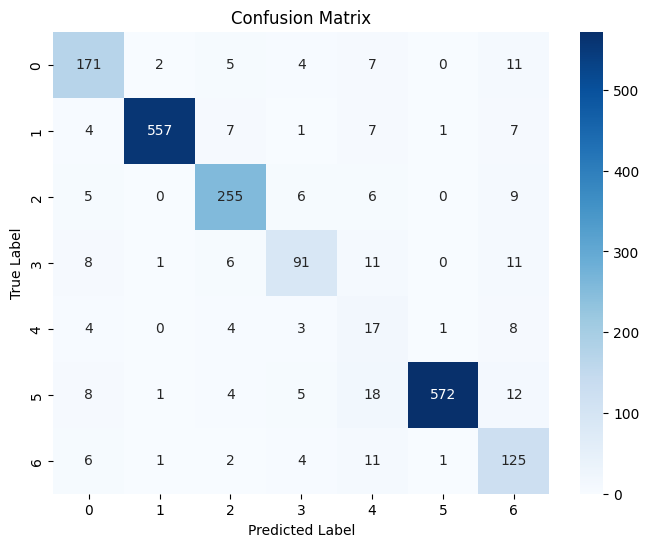

In [24]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(8,6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title("Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.show()

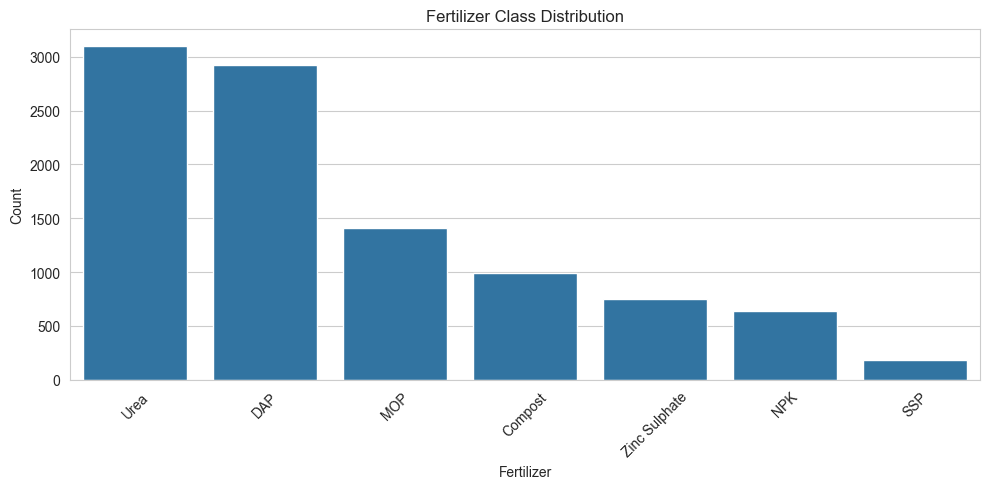

In [27]:
# ----------------------------------------------------------
# 1. Class Distribution
# ----------------------------------------------------------
plt.figure(figsize=(10,5))
sns.countplot(x=y_raw, order=y_raw.value_counts().index)
plt.xticks(rotation=45)
plt.title("Fertilizer Class Distribution")
plt.xlabel("Fertilizer")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

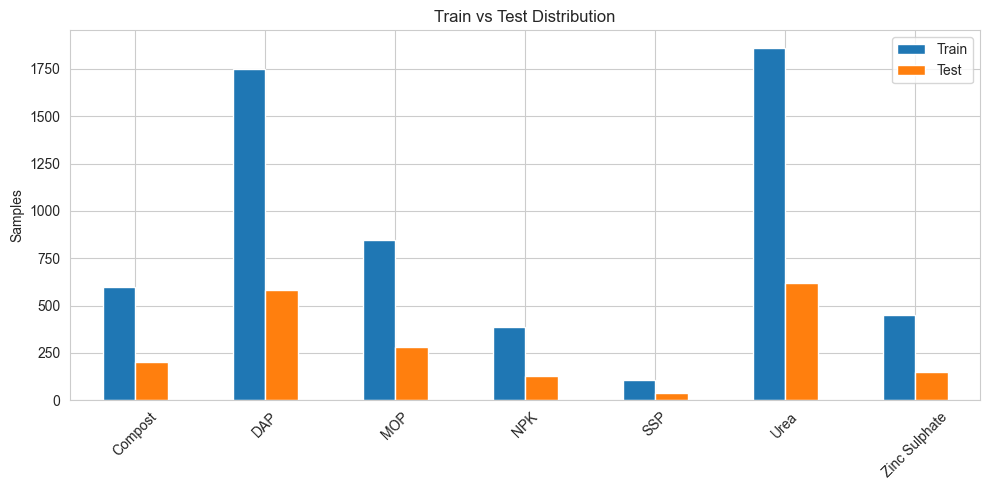

In [28]:
# ----------------------------------------------------------
# 2. Train/Test Distribution
# ----------------------------------------------------------
fig, ax = plt.subplots(figsize=(10,5))

train_counts = pd.Series(
    label_encoder.inverse_transform(y_train)
).value_counts().sort_index()

test_counts = pd.Series(
    label_encoder.inverse_transform(y_test)
).value_counts().sort_index()

df_dist = pd.DataFrame({
    "Train": train_counts,
    "Test": test_counts
}).fillna(0)

df_dist.plot(kind="bar", ax=ax)
plt.title("Train vs Test Distribution")
plt.ylabel("Samples")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


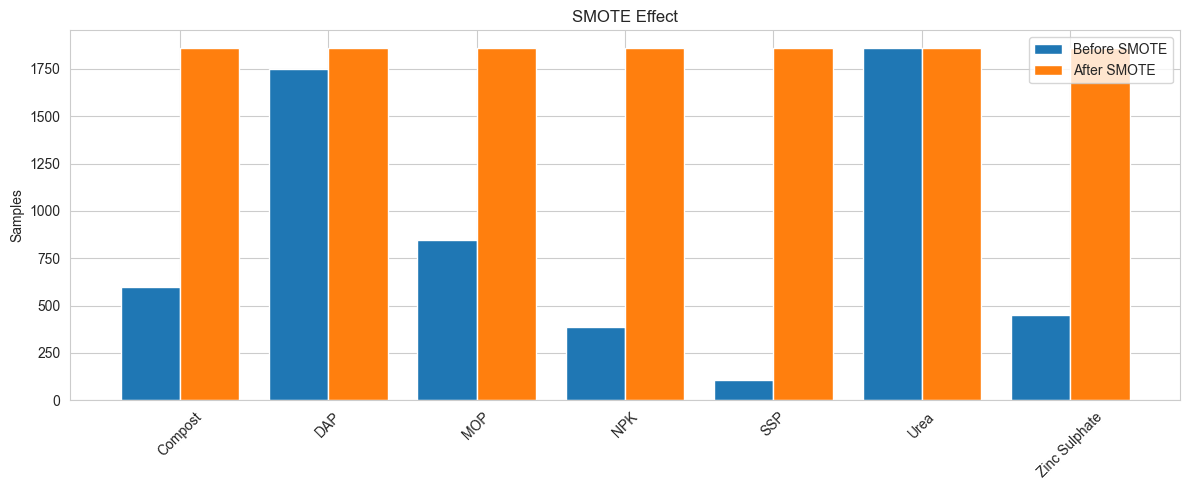

In [29]:
# ----------------------------------------------------------
# 3. SMOTE Before vs After
# ----------------------------------------------------------
before = pd.Series(y_train).value_counts().sort_index()
after = pd.Series(y_train_res).value_counts().sort_index()

labels = label_encoder.inverse_transform(before.index)

x = np.arange(len(labels))
width = 0.4

plt.figure(figsize=(12,5))
plt.bar(x-width/2, before.values, width, label="Before SMOTE")
plt.bar(x+width/2, after.values, width, label="After SMOTE")

plt.xticks(x, labels, rotation=45)
plt.ylabel("Samples")
plt.title("SMOTE Effect")
plt.legend()
plt.tight_layout()
plt.show()


<Figure size 900x700 with 0 Axes>

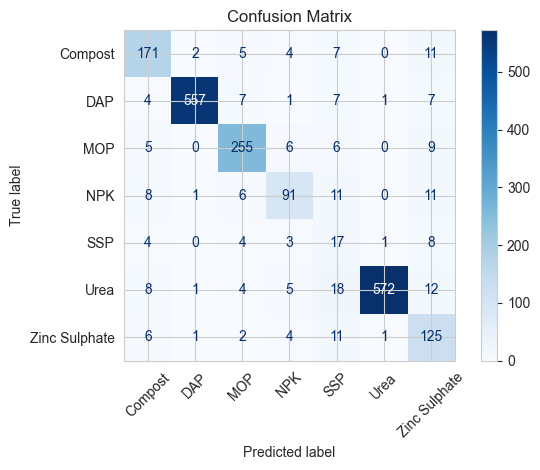

In [30]:
# ----------------------------------------------------------
# 4. Confusion Matrix
# ----------------------------------------------------------
plt.figure(figsize=(9,7))
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=label_encoder.classes_,
    cmap="Blues",
    xticks_rotation=45
)
plt.title("Confusion Matrix")
plt.tight_layout()
plt.show()


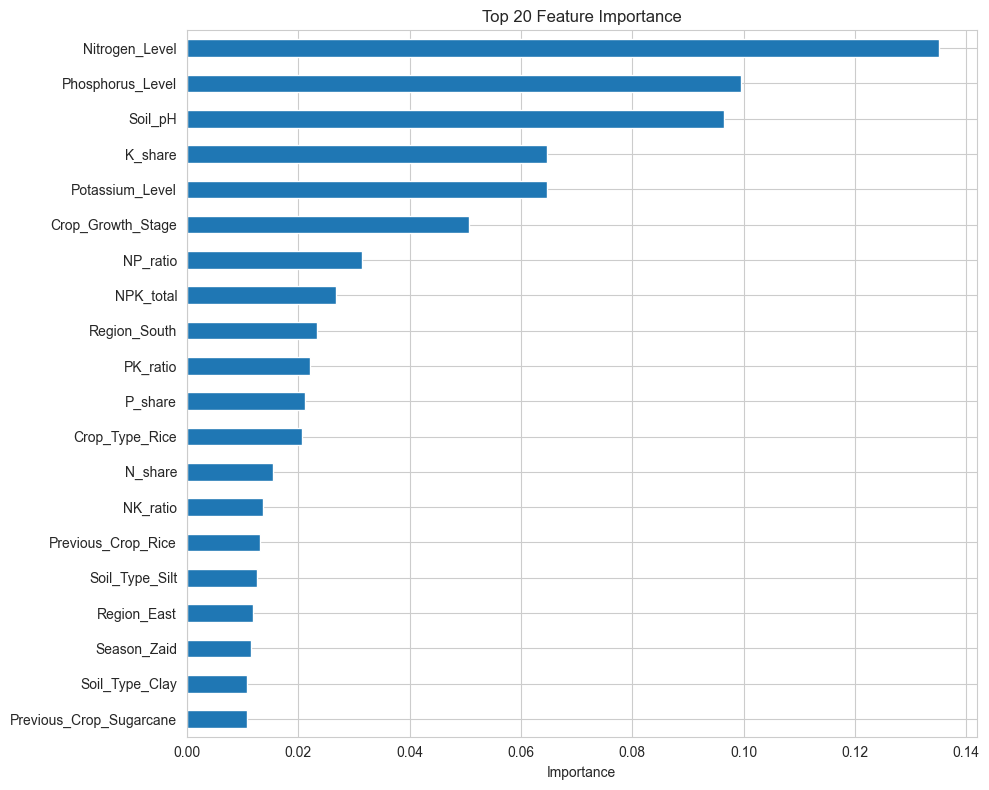

In [31]:
# ----------------------------------------------------------
# 5. Feature Importance
# ----------------------------------------------------------
importance = pd.Series(
    model.feature_importances_,
    index=X_train.columns
).sort_values(ascending=False)

plt.figure(figsize=(10,8))
importance.head(20).plot(kind="barh")
plt.gca().invert_yaxis()
plt.title("Top 20 Feature Importance")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

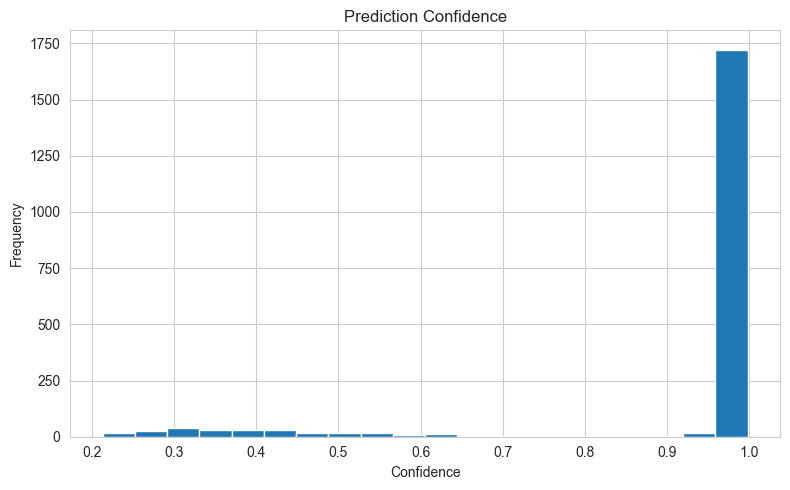

In [32]:
# ----------------------------------------------------------
# 6. Prediction Confidence Distribution
# ----------------------------------------------------------
confidence = np.max(y_proba, axis=1)

plt.figure(figsize=(8,5))
plt.hist(confidence, bins=20)
plt.title("Prediction Confidence")
plt.xlabel("Confidence")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

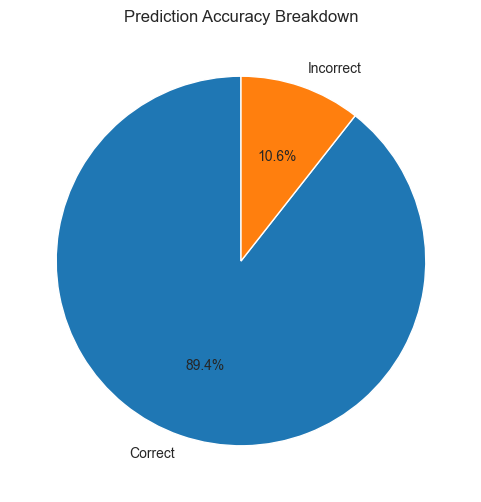

In [33]:
# ----------------------------------------------------------
# 7. Correct vs Wrong Predictions
# ----------------------------------------------------------
correct = np.sum(y_pred == y_test)
incorrect = np.sum(y_pred != y_test)

plt.figure(figsize=(6,6))
plt.pie(
    [correct, incorrect],
    labels=["Correct", "Incorrect"],
    autopct="%1.1f%%",
    startangle=90
)
plt.title("Prediction Accuracy Breakdown")
plt.show()

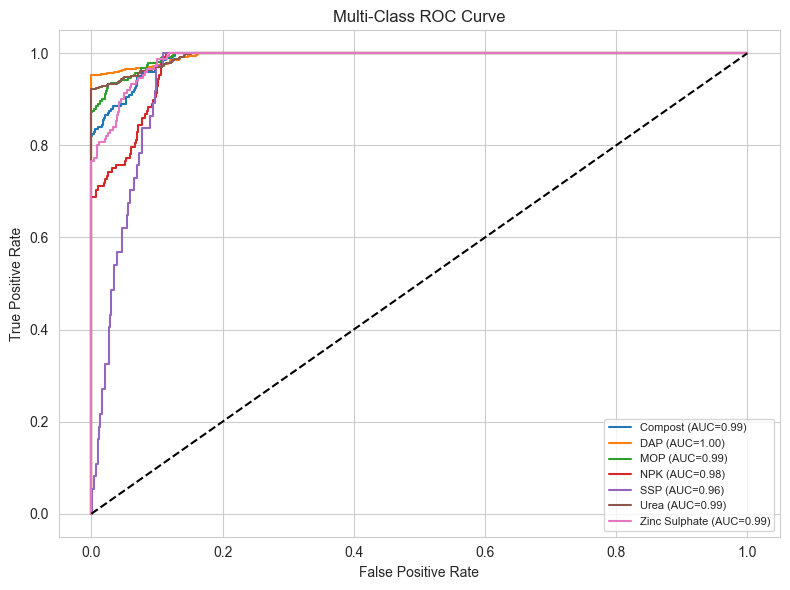

In [34]:
# ----------------------------------------------------------
# 8. ROC Curve (Multi-Class)
# ----------------------------------------------------------
classes = np.unique(y_test)
y_test_bin = label_binarize(y_test, classes=classes)

plt.figure(figsize=(8,6))

for i in range(len(classes)):
    fpr, tpr, _ = roc_curve(y_test_bin[:, i], y_proba[:, i])
    roc_auc = auc(fpr, tpr)
    plt.plot(
        fpr,
        tpr,
        label=f"{label_encoder.classes_[i]} (AUC={roc_auc:.2f})"
    )

plt.plot([0,1],[0,1],'k--')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Multi-Class ROC Curve")
plt.legend(fontsize=8)
plt.tight_layout()
plt.show()

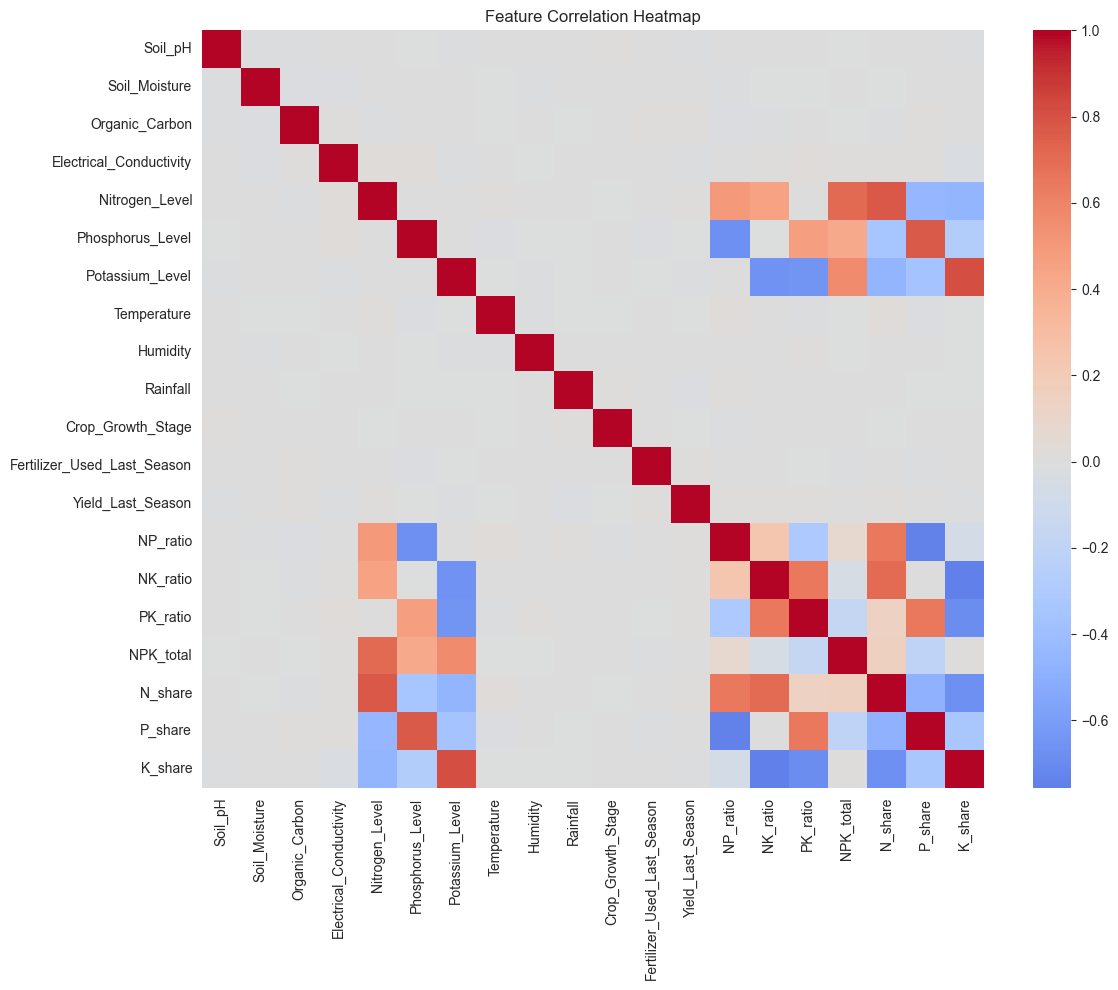

In [35]:
# ----------------------------------------------------------
# 9. Correlation Heatmap (Numeric Features)
# ----------------------------------------------------------
plt.figure(figsize=(12,10))
corr = df.select_dtypes(include=np.number).corr()

sns.heatmap(
    corr,
    cmap="coolwarm",
    center=0
)

plt.title("Feature Correlation Heatmap")
plt.tight_layout()
plt.show()

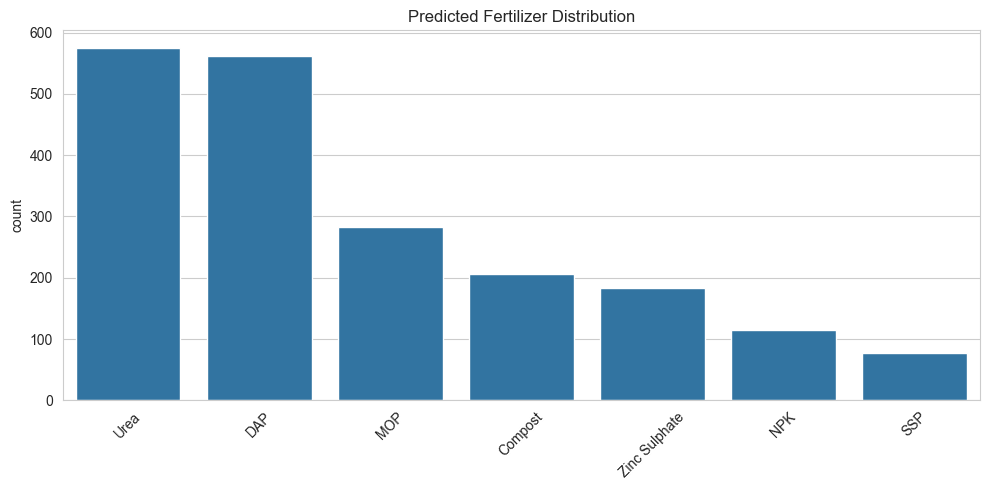

In [36]:
# ----------------------------------------------------------
# 10. Top Predicted Fertilizers
# ----------------------------------------------------------
pred_names = label_encoder.inverse_transform(y_pred)

plt.figure(figsize=(10,5))
sns.countplot(
    x=pred_names,
    order=pd.Series(pred_names).value_counts().index
)
plt.xticks(rotation=45)
plt.title("Predicted Fertilizer Distribution")
plt.tight_layout()
plt.show()